# Figure 14.1 — Thermionic emission, tunneling, and space-charge current

Thermionic transport samples the high-energy tail, tunneling samples the evanescent wave, and strong injection couples current to Poisson electrostatics.

## Direct NumPy calculation

The governing relations are evaluated explicitly before the reusable course implementation is imported.

300 K thermal voltage = 0.025852 V
T(E=0.4 eV, d=1 nm) = 1.3633e-01


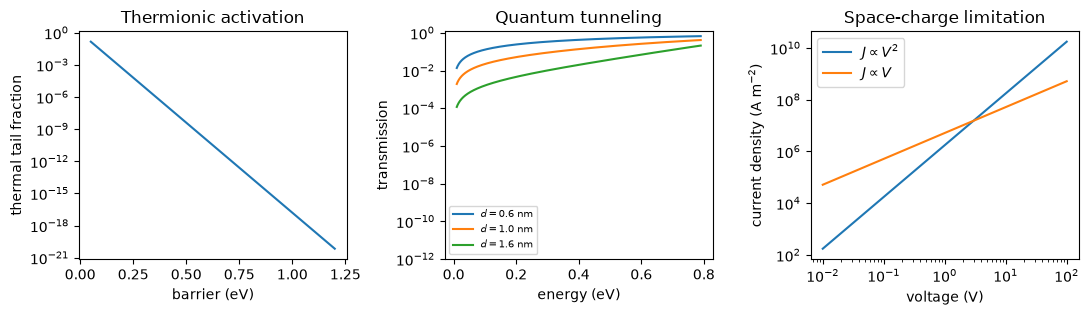

In [1]:
import numpy as np
import matplotlib.pyplot as plt

q = 1.602_176_634e-19
k_B = 1.380_649e-23
hbar = 1.054_571_817e-34
m_0 = 9.109_383_7139e-31
eps_0 = 8.854_187_8128e-12
T = 300.0
V_T = k_B*T/q

barrier_ev = np.linspace(0.05, 1.2, 500)
thermal_tail = np.exp(-barrier_ev/V_T)
energy_ev = np.linspace(0.01, 0.79, 600)
barrier_j = 0.8*q
mass = 0.26*m_0

def transmission(width_nm):
    E = energy_ev*q
    kappa = np.sqrt(2*mass*(barrier_j-E))/hbar
    return 1/(1 + barrier_j**2*np.sinh(np.minimum(kappa*width_nm*1e-9, 350))**2/(4*E*(barrier_j-E)))

assert np.all(transmission(1.2) < transmission(0.6))
voltage = np.logspace(-2, 2, 500)
eps = 11.7*eps_0
mu, length, v_sat = 0.12, 2e-6, 1e5
J_mu = 9*eps*mu*voltage**2/(8*length**3)
J_sat = 2*eps*v_sat*voltage/length**2
assert np.isclose(J_mu[-1]/J_mu[-2], (voltage[-1]/voltage[-2])**2)

fig, axes = plt.subplots(1, 3, figsize=(11.0, 3.25))
axes[0].semilogy(barrier_ev, thermal_tail)
axes[0].set(xlabel="barrier (eV)", ylabel="thermal tail fraction", title="Thermionic activation")
for width in (0.6, 1.0, 1.6):
    axes[1].semilogy(energy_ev, transmission(width), label=fr"$d={width}$ nm")
axes[1].set(xlabel="energy (eV)", ylabel="transmission", title="Quantum tunneling", ylim=(1e-12, 1.2))
axes[1].legend(fontsize=7)
axes[2].loglog(voltage, J_mu, label=r"$J\propto V^2$")
axes[2].loglog(voltage, J_sat, label=r"$J\propto V$")
axes[2].set(xlabel="voltage (V)", ylabel=r"current density (A m$^{-2}$)", title="Space-charge limitation")
axes[2].legend()
print(f"300 K thermal voltage = {V_T:.6f} V")
print(f"T(E=0.4 eV, d=1 nm) = {transmission(1.0)[np.argmin(abs(energy_ev-0.4))]:.4e}")
fig.tight_layout()
plt.show()

## Reusable publication implementation

The tested course implementation writes the deterministic PDF used by the manuscript.

In [2]:
import sys
from pathlib import Path

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "main.tex").exists()
)
sys.path.insert(0, str(ROOT / "figures" / "src"))

from semphy.transport_extensions import barrier_space_charge_figure

barrier_space_charge_figure()
print("wrote transport-barriers-space-charge.pdf")

wrote transport-barriers-space-charge.pdf
